# Step 1: explore PTB-XL

No AI yet. The goal is to know the data: what's in the label table, how the labels turn into the 5 big
categories, and what a normal ECG and an MI look like as numbers. The helper functions live in
`ecg_common.py` next to this notebook, so every step loads the data the same way.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import ecg_common as ec

## The label table

`load_labels()` reads `ptbxl_database.csv`: one row per ECG. The `scp_codes` column is text that looks like a
dictionary (`{'NORM': 100.0, 'SR': 0.0}`), so it gets turned into a real one. The number is how sure the
cardiologist was, in percent (0 = no number recorded). Then every code is looked up in `scp_statements.csv`
to find which of the 5 big categories it belongs to. That's the `classes` column.

In [2]:
db = ec.load_labels()
print(len(db), "ECGs from", db.patient_id.nunique(), "patients")
db[["age", "sex", "scp_codes", "classes", "strat_fold"]].head()

21799 ECGs from 18869 patients


,age,sex,scp_codes,classes,strat_fold
ecg_id,,,,,
1,56.0,1,"{'NORM': 100.0, 'LVOLT': 0.0, 'SR': 0.0}",[NORM],3
2,19.0,0,"{'NORM': 80.0, 'SBRAD': 0.0}",[NORM],2
3,37.0,1,"{'NORM': 100.0, 'SR': 0.0}",[NORM],5
4,24.0,0,"{'NORM': 100.0, 'SR': 0.0}",[NORM],3
5,19.0,1,"{'NORM': 100.0, 'SR': 0.0}",[NORM],4


## How many ECGs in each category

One ECG can be in more than one category (an old MI plus a conduction problem, say), so these add up to more
than 21,799. A few hundred ECGs only have rhythm or shape codes, so they're in no category at all.

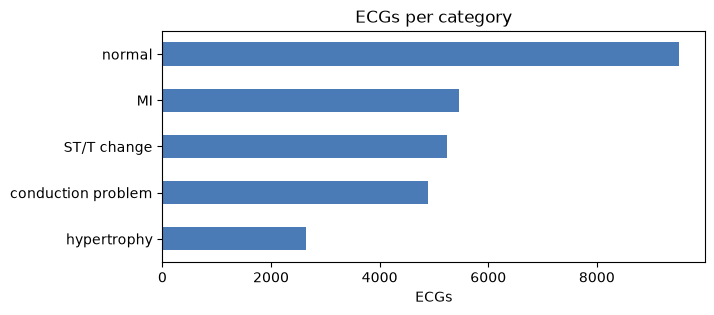

normal                9514
MI                    5469
ST/T change           5235
conduction problem    4898
hypertrophy           2649
in no category: 411
normal and nothing else: 9069


In [3]:
names = {"NORM": "normal", "MI": "MI", "STTC": "ST/T change", "CD": "conduction problem", "HYP": "hypertrophy"}
counts = db[ec.CLASSES].sum().rename(names)
ax = counts.plot.barh(color="#4a7bb7", title="ECGs per category", figsize=(7, 3))
ax.invert_yaxis()
ax.set_xlabel("ECGs")
plt.show()
print(counts.to_string())
print("in no category:", (db.classes.str.len() == 0).sum())
print("normal and nothing else:", (db.classes.apply(lambda c: c == ["NORM"])).sum())

## Which codes count as MI

The MI category is a group of codes, mostly by where the infarct is. The `count` column is how many ECGs
carry each code.

In [4]:
scp = pd.read_csv(ec.DATA / "scp_statements.csv", index_col=0)
mi_codes = scp[(scp.diagnostic == 1) & (scp.diagnostic_class == "MI")][["description"]].copy()
mi_codes["count"] = [db.scp_codes.apply(lambda c: code in c).sum() for code in mi_codes.index]
mi_codes.sort_values("count", ascending=False)

,description,count
IMI,inferior myocardial infarction,2676
ASMI,anteroseptal myocardial infarction,2357
ILMI,inferolateral myocardial infarction,478
AMI,anterior myocardial infarction,353
ALMI,anterolateral myocardial infarction,288
INJAS,subendocardial injury in anteroseptal leads,214
LMI,lateral myocardial infarction,201
INJAL,subendocardial injury in anterolateral leads,145
IPLMI,inferoposterolateral myocardial infarction,51
IPMI,inferoposterior myocardial infarction,33


## Loading every ECG

`load_signals()` reads all 21,799 files into one array and saves a copy (`data/X100.npy`, about 1 GB), so
later notebooks load everything in seconds. The shape is (ECGs, time steps, leads): 1,000 time steps is
10 seconds at 100 per second, and the values are millivolts.

In [5]:
X = ec.load_signals(db)
print(X.shape, X.dtype)

(21799, 1000, 12) float32


## A normal ECG next to an MI

Two ECGs the cardiologists were sure about (likelihood 100), both checked by a person, with no noise or
electrode problems flagged. Plotted like 12-lead paper: a big square is 0.2 s wide and 0.5 mV tall. Only the
first 5 of the 10 seconds are shown so the beats are readable.

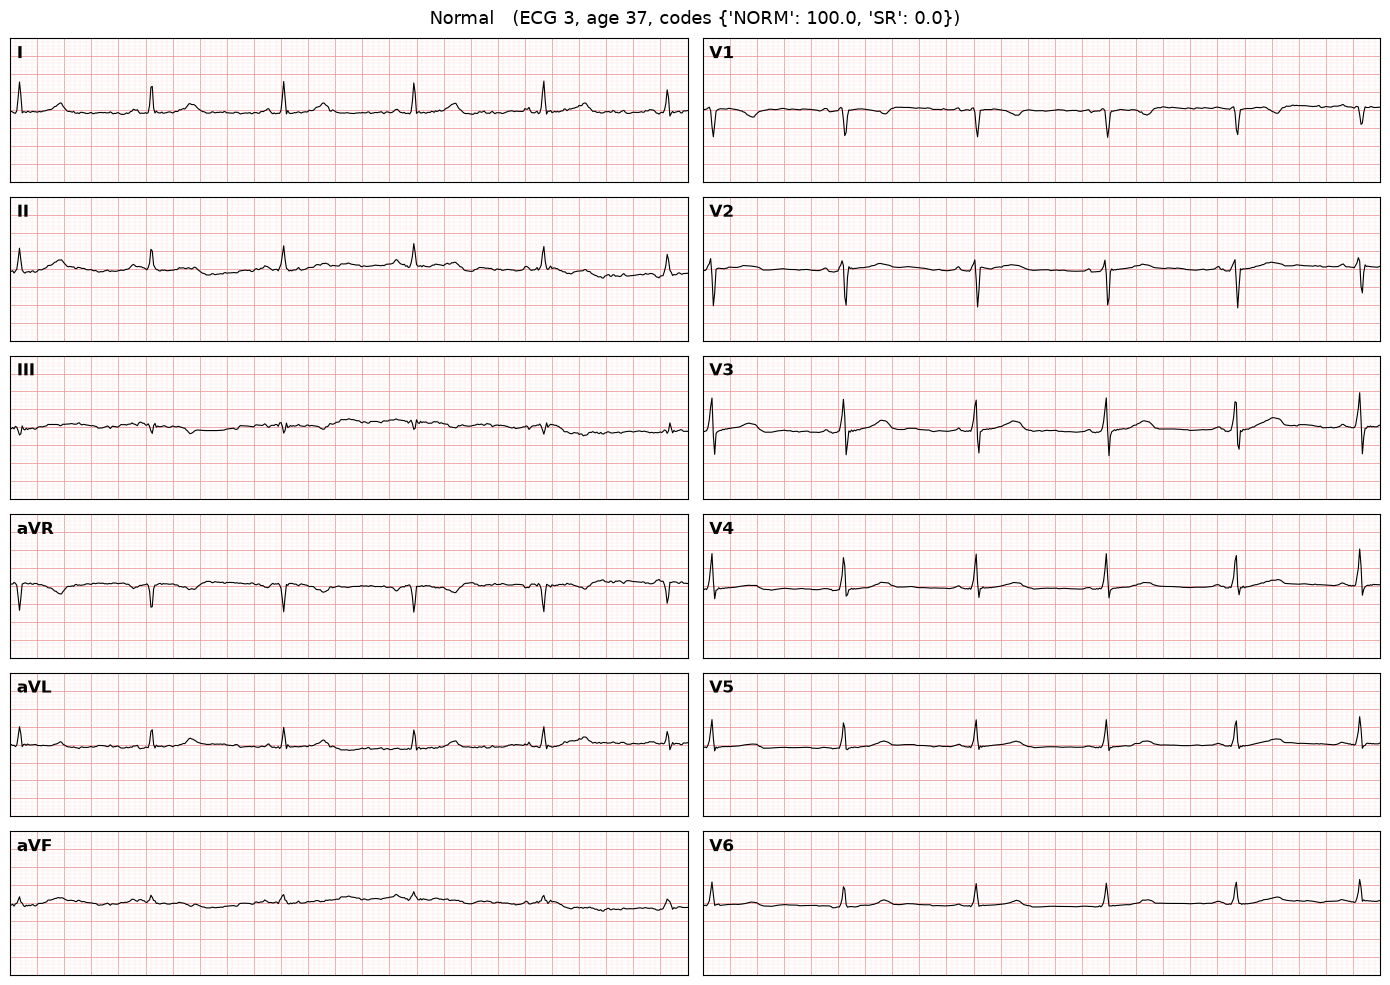

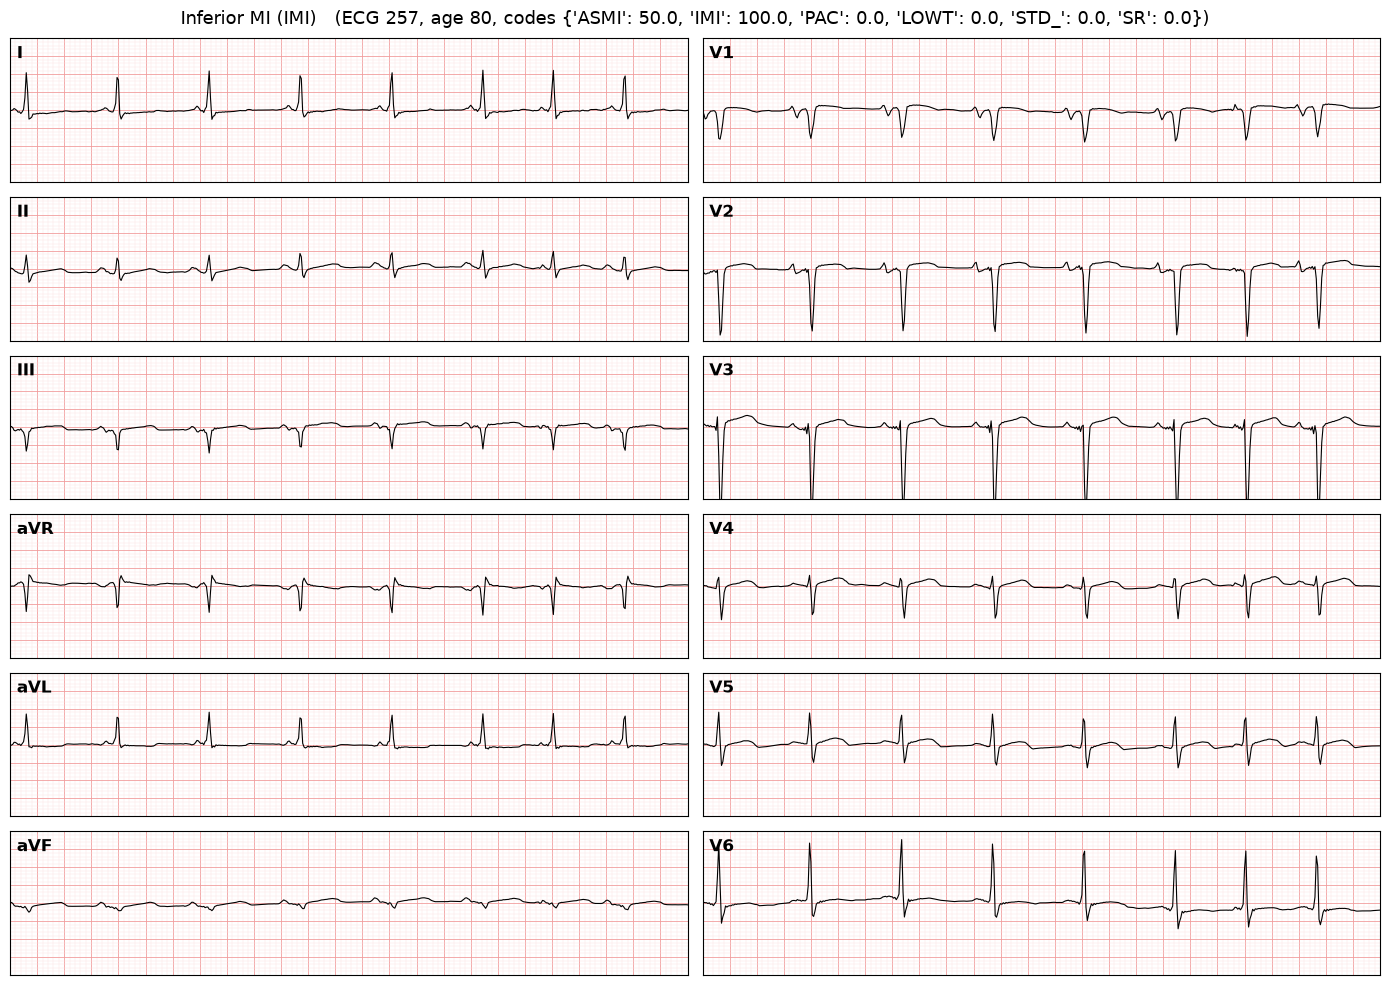

In [6]:
clean = db.validated_by_human & db[["baseline_drift", "static_noise", "burst_noise", "electrodes_problems"]].isna().all(axis=1)
normal_id = db[clean & db.classes.apply(lambda c: c == ["NORM"]) & db.scp_codes.apply(lambda c: c.get("NORM") == 100)].index[0]
mi_id = db[clean & db.classes.apply(lambda c: c == ["MI"]) & db.scp_codes.apply(lambda c: c.get("IMI") == 100)].index[0]

ec.plot_12lead(X, db, normal_id, "Normal", "figures/normal_ecg.png")
ec.plot_12lead(X, db, mi_id, "Inferior MI (IMI)", "figures/mi_ecg.png")

**What to look for.** Compare V2 and V3: in the normal ECG each beat has a clear upward spike (the R wave), but in
the MI ECG those beats point almost straight down. Lead III in the MI ECG also starts each beat with a dip
(a Q wave). Dips like these are classic signs of an older infarct, which is why this ECG is coded inferior MI at
100% and anteroseptal MI at 50%. Also notice the ages, 37 against 80. That matters in step 2.

## What this step showed

- 21,799 ECGs from 18,869 patients. 9,069 are normal and nothing else; 5,469 have an MI.
- Each ECG is a grid of numbers: 1,000 time steps by 12 leads. That's all a model will ever see.
- Next, step 2 splits the data the right way and works out the score to beat.